In [1]:
#Write a program to implement the local binary pattern on gray scale image.
%pip install opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:4: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saraj\AppData\Local\Temp\ipykernel_29072\886636997.py:4: SyntaxWarning: invalid escape sequence '\d'
  img = cv2.imread("D:\doll.jpg", cv2.IMREAD_GRAYSCALE)


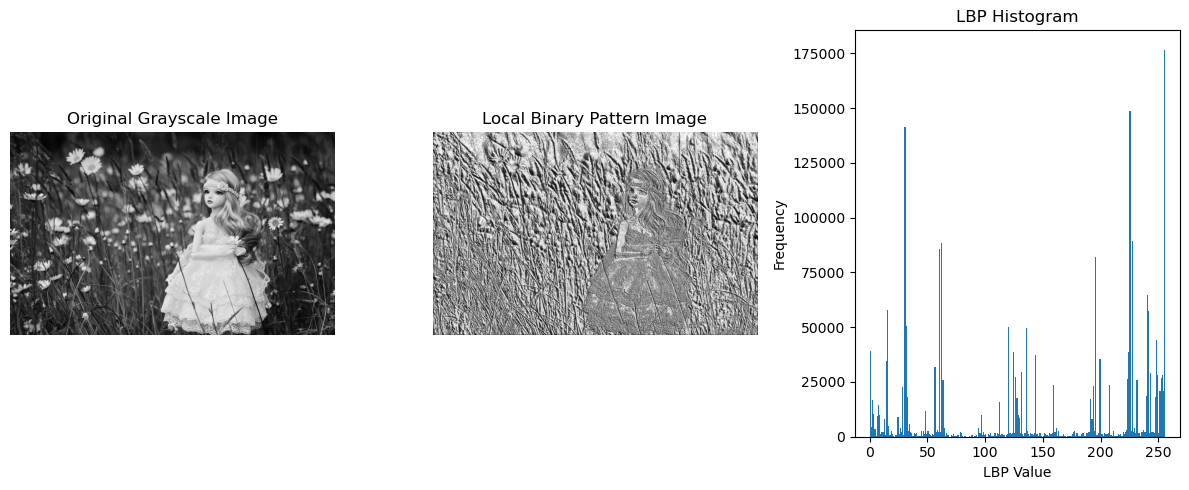

Local Binary Pattern implemented successfully.
Output saved as lbp_output.jpg


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
img = cv2.imread("D:\doll.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")
rows, cols = img.shape
lbp_image = np.zeros((rows, cols), dtype=np.uint8)

for i in range(1, rows - 1):
    for j in range(1, cols - 1):

        center = img[i, j]
        neighbors = [
            img[i-1, j-1],  # Top-left
            img[i-1, j],    # Top
            img[i-1, j+1],  # Top-right
            img[i, j+1],    # Right
            img[i+1, j+1], # Bottom-right
            img[i+1, j],    # Bottom
            img[i+1, j-1],  # Bottom-left
            img[i, j-1]     # Left
        ]

        lbp_value = 0

        for k in range(8):
            if neighbors[k] >= center:
                lbp_value += 2 ** k
        lbp_image[i, j] = lbp_value

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(lbp_image, cmap="gray")
plt.title("Local Binary Pattern Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.hist(lbp_image.ravel(), bins=256, range=(0, 256))
plt.title("LBP Histogram")
plt.xlabel("LBP Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
cv2.imwrite("lbp_output.jpg", lbp_image)
print("Local Binary Pattern implemented successfully.")
print("Output saved as lbp_output.jpg")

<>:14: SyntaxWarning: invalid escape sequence '\d'
<>:14: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saraj\AppData\Local\Temp\ipykernel_29072\498173048.py:14: SyntaxWarning: invalid escape sequence '\d'
  img = cv2.imread("D:\doll.jpg", cv2.IMREAD_GRAYSCALE)


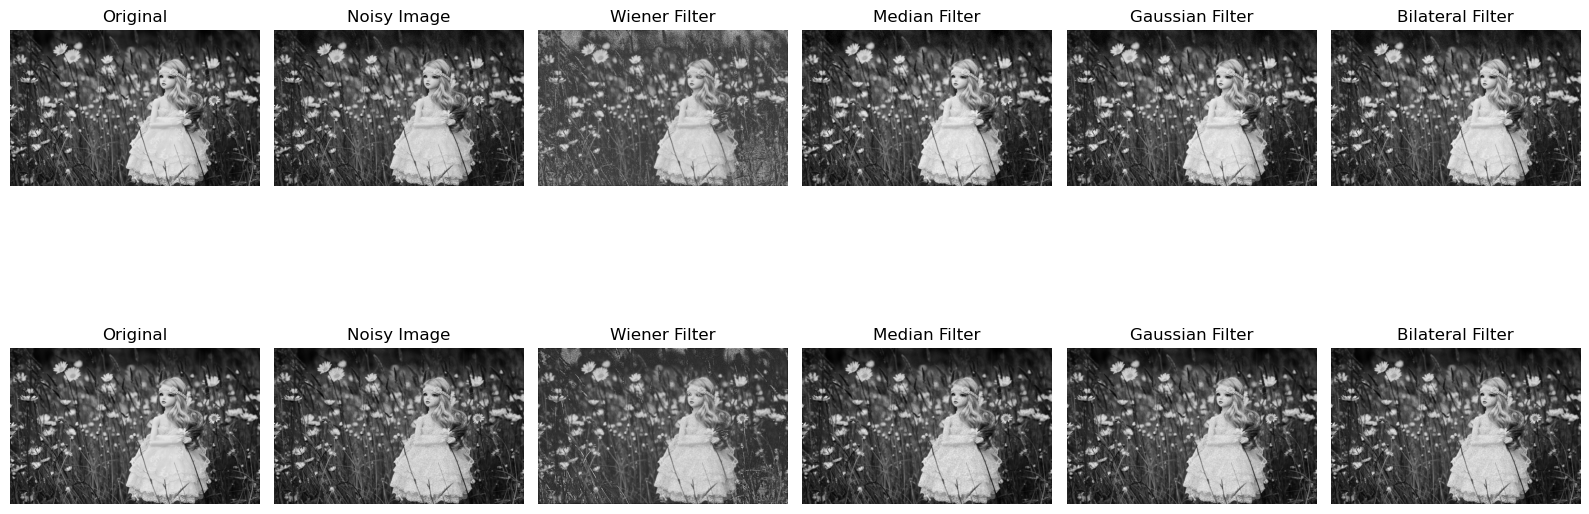

Gaussian and Speckle noise generated successfully.
All four filters applied successfully.
Output images saved successfully.


In [5]:
# Write a program to denoise the input image corrupted by Gaussian and Speckle noise by using following filters (3x3 or 5x5 window).  
        #         (a) Weiner filter  
         #        (b) Median filtering  
          #       (c) Gaussian filter  
           #      (d) Bilateral filter 


import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read input image in grayscale
img = cv2.imread("D:\doll.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")

# Convert image to float
img_float = img.astype(np.float32)

np.random.seed(42)

gaussian_noise = np.random.normal(0, 20, img.shape)
gaussian_noisy = img_float + gaussian_noise
gaussian_noisy = np.clip(gaussian_noisy, 0, 255).astype(np.uint8)
speckle_noise = np.random.normal(0, 0.2, img.shape)
speckle_noisy = img_float + img_float * speckle_noise
speckle_noisy = np.clip(speckle_noisy, 0, 255).astype(np.uint8)

def apply_filters(noisy_img):
    wiener_img = wiener(noisy_img, (5, 5))
    wiener_img = np.clip(wiener_img, 0, 255).astype(np.uint8)
    median_img = cv2.medianBlur(noisy_img, 5)
    gaussian_img = cv2.GaussianBlur(noisy_img, (5, 5), 0)
    bilateral_img = cv2.bilateralFilter(
        noisy_img, 5, 75, 75
    )

    return wiener_img, median_img, gaussian_img, bilateral_img

g_wiener, g_median, g_gaussian, g_bilateral = apply_filters(
    gaussian_noisy
)

s_wiener, s_median, s_gaussian, s_bilateral = apply_filters(
    speckle_noisy
)

titles = [
    "Original",
    "Noisy Image",
    "Wiener Filter",
    "Median Filter",
    "Gaussian Filter",
    "Bilateral Filter"
]

gaussian_results = [
    img,
    gaussian_noisy,
    g_wiener,
    g_median,
    g_gaussian,
    g_bilateral
]

speckle_results = [
    img,
    speckle_noisy,
    s_wiener,
    s_median,
    s_gaussian,
    s_bilateral
]

plt.figure(figsize=(16, 8))

for i, result in enumerate(gaussian_results):
    plt.subplot(2, 6, i + 1)
    plt.imshow(result, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")
for i, result in enumerate(speckle_results):
    plt.subplot(2, 6, i + 7)
    plt.imshow(result, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()
cv2.imwrite("gaussian_noisy.jpg", gaussian_noisy)
cv2.imwrite("speckle_noisy.jpg", speckle_noisy)

cv2.imwrite("gaussian_wiener.jpg", g_wiener)
cv2.imwrite("gaussian_median.jpg", g_median)
cv2.imwrite("gaussian_filtered.jpg", g_gaussian)
cv2.imwrite("gaussian_bilateral.jpg", g_bilateral)

cv2.imwrite("speckle_wiener.jpg", s_wiener)
cv2.imwrite("speckle_median.jpg", s_median)
cv2.imwrite("speckle_filtered.jpg", s_gaussian)
cv2.imwrite("speckle_bilateral.jpg", s_bilateral)

print("Gaussian and Speckle noise generated successfully.")
print("All four filters applied successfully.")
print("Output images saved successfully.")